In [1]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


I0000 00:00:1794837005.187652   93456 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Sélection du scope de données à traiter (sources, défauts, diamètres, positions, charges, canaux)
# On importe uniquement les signaux DE pour faire l'analyse de corrélation des features pour avoir une séparation de classe nette.
selection = data.selectionner(
    sources=("12kDE", "Normal"),
    # defauts=("IR", "B", "OR"),
    # diametres=(7, 14, 21), positions_or=("6",),
    # charges=(0, 1, 2, 3),
    canaux={"12kDE": ("DE",), 
            "Normal": ("DE")},
)

In [3]:
# Importation des données sélectionnées et ajout des indicateurs temporels et spectraux
table = features.construire_table(selection, data.charger)

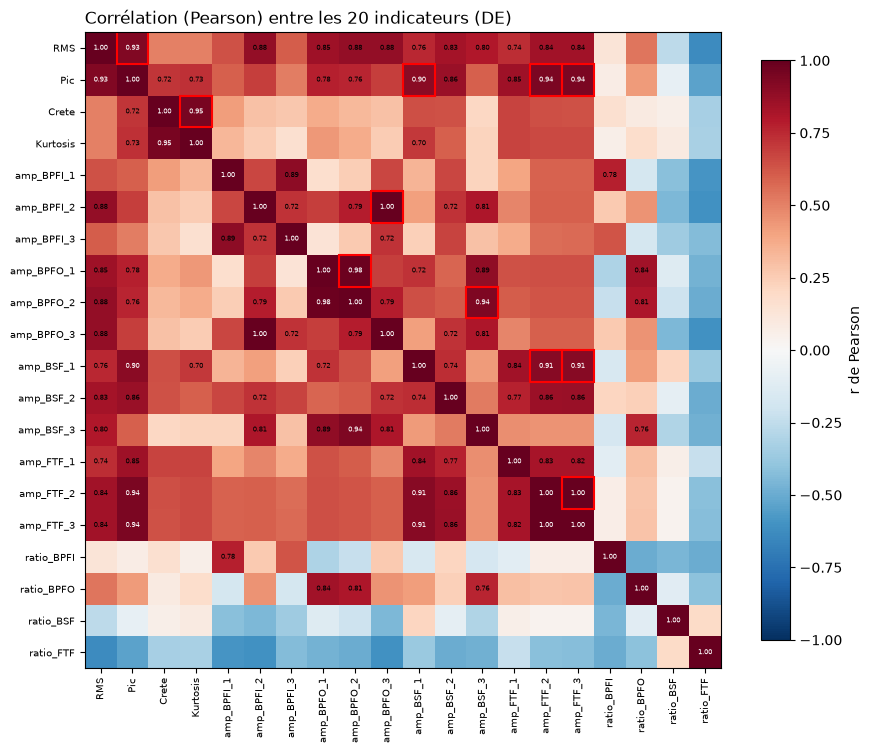

     feature_1   feature_2      r
5   amp_BPFI_2  amp_BPFO_3  1.000
10   amp_FTF_2   amp_FTF_3  0.996
6   amp_BPFO_1  amp_BPFO_2  0.978
4        Crete    Kurtosis  0.946
2          Pic   amp_FTF_2  0.941
3          Pic   amp_FTF_3  0.941
7   amp_BPFO_2   amp_BSF_3  0.935
0          RMS         Pic  0.926
8    amp_BSF_1   amp_FTF_2  0.913
9    amp_BSF_1   amp_FTF_3  0.912
1          Pic   amp_BSF_1  0.903


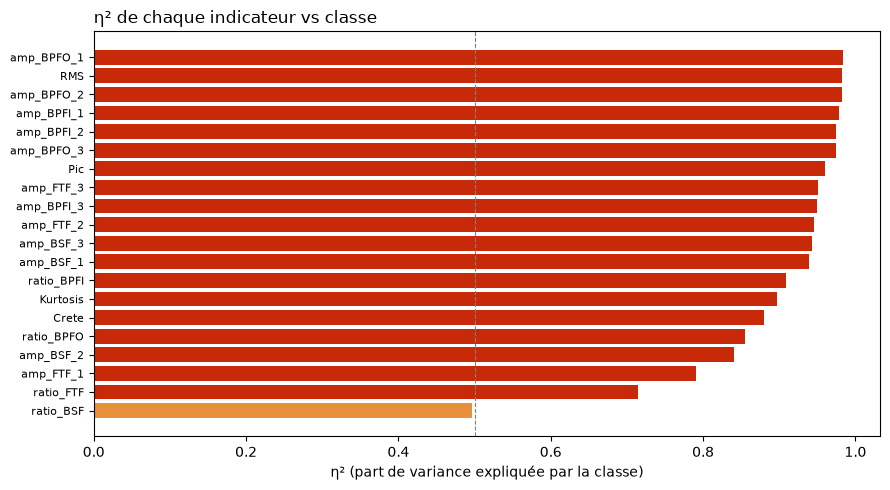

amp_BPFO_1    0.983
RMS           0.982
amp_BPFO_2    0.982
amp_BPFI_1    0.978
amp_BPFI_2    0.975
amp_BPFO_3    0.975
Pic           0.960
amp_FTF_3     0.951
amp_BPFI_3    0.949
amp_FTF_2     0.945
amp_BSF_3     0.942
amp_BSF_1     0.939
ratio_BPFI    0.909
Kurtosis      0.897
Crete         0.880
ratio_BPFO    0.855
amp_BSF_2     0.840
amp_FTF_1     0.790
ratio_FTF     0.715
ratio_BSF     0.497
dtype: float64


In [4]:
# Génération analyses de corrélation et d'importance des features
COLS = indicateurs.COLONNES_TEMPORELS + indicateurs.COLONNES_SPECTRAUX
X = table[COLS]              # Mes features
y = table["classe"]          # Mon target >>>> /!\ Les eta2 dépendes du target, donc à refaire suivant l'objectif !!

# ---------- VISUEL 1 : heatmap de corrélation ----------
def heatmap_correlation(X, seuil=0.9, titre=""):
    ordre = ([c for c in X.columns if c in ("RMS", "Pic", "Crete", "Kurtosis")]
             + sorted(c for c in X.columns if c.startswith("amp_"))
             + sorted(c for c in X.columns if c.startswith("ratio_"))
             + [c for c in X.columns if c == "f_pic"])
    X = X[ordre]
    corr = X.corr(method="pearson")
    n = len(ordre)
    fig, ax = plt.subplots(figsize=(max(8, n*0.45), max(7, n*0.4)))
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(n), ordre, rotation=90, fontsize=7)
    ax.set_yticks(range(n), ordre, fontsize=7)
    for i in range(n):
        for j in range(n):
            v = corr.values[i, j]
            if abs(v) >= 0.7:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5,
                        color="white" if abs(v) > seuil else "black")
    for i in range(n):                       # cadre rouge sur les paires très corrélées
        for j in range(i+1, n):
            if abs(corr.values[i, j]) >= seuil:
                ax.add_patch(plt.Rectangle((j-0.5, i-0.5), 1, 1,
                                           fill=False, edgecolor="red", lw=1.5))
    ax.set_title(titre, loc="left")
    fig.colorbar(im, ax=ax, shrink=0.8, label="r de Pearson")
    fig.tight_layout()
    plt.show()
    return corr

corr = heatmap_correlation(X, seuil=0.9, titre=f"Corrélation (Pearson) entre les {X.shape[1]} indicateurs (DE)")

# ---------- VISUEL 2 : paires redondantes (|r| >= seuil) ----------
def paires_redondantes(corr, seuil=0.9):
    cols, paires = corr.columns, []
    for i in range(len(cols)):
        for j in range(i+1, len(cols)):
            if abs(corr.values[i, j]) >= seuil:
                paires.append((cols[i], cols[j], round(corr.values[i, j], 3)))
    return pd.DataFrame(paires, columns=["feature_1", "feature_2", "r"]).sort_values("r")

print(paires_redondantes(corr, seuil=0.9).sort_values("r", ascending=False))

# ---------- VISUEL 3 : eta² feature -> classe ----------
def eta2(X, y):
    """eta² = SS_inter / SS_total (ANOVA à un facteur) : part de variance
    de la feature expliquée par la classe, entre 0 et 1."""
    y = np.asarray(y)
    out = {}
    for c in X.columns:
        x = np.asarray(X[c], dtype=float)
        ss_t = ((x - x.mean())**2).sum()
        ss_b = sum(len(g)*(g.mean() - x.mean())**2 for g in [x[y == k] for k in np.unique(y)])
        out[c] = ss_b / ss_t if ss_t > 0 else 0.0
    return pd.Series(out).sort_values(ascending=False)

def barplot_eta2(X, y, titre=""):
    e = eta2(X, y)
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ["#C82909" if v >= 0.5 else "#E8913A" if v >= 0.2 else "#9BB7D4" for v in e]
    ax.barh(range(len(e)), e.values, color=colors)
    ax.set_yticks(range(len(e)), e.index, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("η² (part de variance expliquée par la classe)")
    ax.set_title(titre, loc="left")
    ax.axvline(0.5, color="grey", ls="--", lw=0.8)
    fig.tight_layout(); plt.show()
    return e

e = barplot_eta2(X, y, titre="η² de chaque indicateur vs classe")
print(e.round(3))